# Movies distribution

Plot release decade and runtime distributions from the Cinémathèque API (`GET /api/movies`).

Requires a reachable backend. Set `API_URL` in `.env` or `notebooks/.env` (e.g. `http://localhost:8000`). The Jupyter kernel does not inherit your terminal. No Django setup, no database access, no API key for read-only requests.

## Setup

In [ ]:
import json
import os
from pathlib import Path
from urllib.error import HTTPError, URLError
from urllib.request import urlopen

import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
from dotenv import load_dotenv
from matplotlib.axes import Axes

DRACULA = {
    "bg": "#000000",
    "bg_secondary": "#1a1a1a",
    "fg": "#f8f8f2",
    "comment": "#6272a4",
    "cyan": "#8be9fd",
    "green": "#50fa7b",
    "orange": "#ffb86c",
    "pink": "#ff79c6",
    "purple": "#bd93f9",
    "red": "#ff5555",
    "yellow": "#f1fa8c",
}

DRACULA_CMAP = mcolors.LinearSegmentedColormap.from_list(
    "dracula",
    [DRACULA["cyan"], DRACULA["pink"]],
)


def setup_dracula_style() -> None:
    plt.rcParams.update(
        {
            "figure.facecolor": DRACULA["bg"],
            "axes.facecolor": DRACULA["bg"],
            "axes.edgecolor": DRACULA["fg"],
            "axes.labelcolor": DRACULA["fg"],
            "axes.titlecolor": DRACULA["fg"],
            "text.color": DRACULA["fg"],
            "xtick.color": DRACULA["fg"],
            "ytick.color": DRACULA["fg"],
            "grid.color": DRACULA["bg_secondary"],
            "font.size": 11,
            "axes.titlesize": 14,
            "axes.titleweight": "bold",
        }
    )


def style_axes(ax: Axes) -> None:
    ax.set_facecolor(DRACULA["bg"])
    ax.tick_params(colors=DRACULA["fg"], labelcolor=DRACULA["fg"])
    ax.grid(
        axis="y",
        color=DRACULA["bg_secondary"],
        alpha=0.9,
        linestyle="-",
        linewidth=0.8,
    )
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color(DRACULA["comment"])
    ax.spines["bottom"].set_color(DRACULA["comment"])


load_dotenv(Path("../.env"))
load_dotenv(Path(".env"), override=True)

api_url = os.getenv("API_URL", f"http://localhost:{os.getenv('API_PORT', '8000')}").rstrip("/")
print(api_url)

setup_dracula_style()

## Load movies from API

In [ ]:
movies_url = f"{api_url}/movies"

try:
    with urlopen(movies_url) as resp:
        data = json.loads(resp.read())
except (HTTPError, URLError) as exc:
    raise RuntimeError(
        f"Failed to fetch movies from {movies_url}. Is the backend running?"
    ) from exc

movies = [
    (m["year"], m["length"])
    for m in data["movies"]
    if m["type"] == "movie"
]

with_year = sum(1 for year, _ in movies if year)
with_length = sum(1 for _, length in movies if length is not None)

print(f"Loaded {len(movies)} movies from {movies_url}.")
print(f"  with year: {with_year}")
print(f"  with length: {with_length}")
if with_length == 0:
    print(
        "No length data found. Run sync_drive with --with-length on the server:\n"
        "  uv run manage.py sync_drive --movies --with-length"
    )

Loaded 479 movies from http://localhost:8007/api/movies.
  with year: 437
  with length: 419


## Movies dates distribution

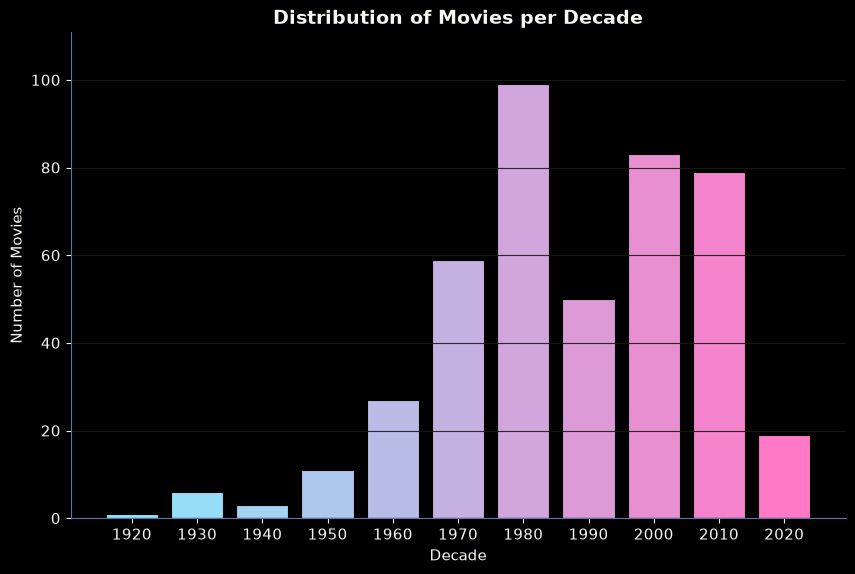

In [28]:
years: list[int] = []
for year, _ in movies:
    if not year:
        continue
    try:
        years.append(int(year))
    except ValueError:
        continue

decade_counts: dict[int, int] = {}
for year in years:
    decade = (year // 10) * 10
    decade_counts[decade] = decade_counts.get(decade, 0) + 1

sorted_decades = sorted(decade_counts.keys())
sorted_counts = [decade_counts[decade] for decade in sorted_decades]
bar_colors = [
    DRACULA_CMAP(i / max(len(sorted_decades) - 1, 1)) for i in range(len(sorted_decades))
]

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.bar(sorted_decades, sorted_counts, width=8, color=bar_colors, edgecolor=DRACULA["bg"], linewidth=0.8)
if sorted_counts:
    ax.set_ylim(0, max(sorted_counts) * 1.12)
for bar in bars:
    bar.set_clip_on(False)

ax.set_xlabel("Decade")
ax.set_ylabel("Number of Movies")
ax.set_title("Distribution of Movies per Decade")
ax.set_xticks(sorted_decades)
style_axes(ax)
fig.subplots_adjust(top=0.92)
plt.show()

## Movies length distribution

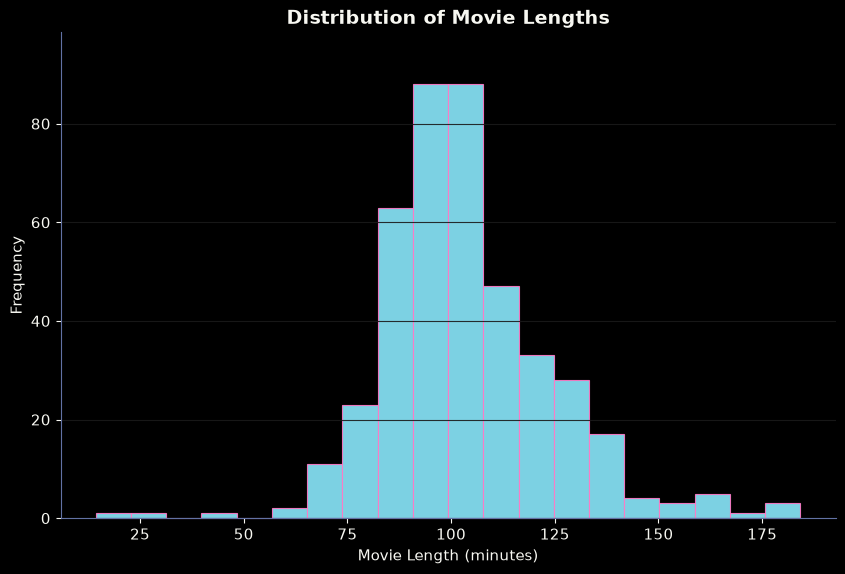

In [29]:
movie_lengths: list[float] = [
    length / 60 for _, length in movies if length is not None
]

fig, ax = plt.subplots(figsize=(10, 6))
counts, _, patches = ax.hist(
    movie_lengths,
    bins=20,
    color=DRACULA["cyan"],
    edgecolor=DRACULA["pink"],
    alpha=0.9,
    linewidth=0.8,
)
if len(counts):
    ax.set_ylim(0, counts.max() * 1.12)
for patch in patches:
    patch.set_clip_on(False)

ax.set_xlabel("Movie Length (minutes)")
ax.set_ylabel("Frequency")
ax.set_title("Distribution of Movie Lengths")
style_axes(ax)
fig.subplots_adjust(top=0.92)
plt.show()

## Movie lengths across decades

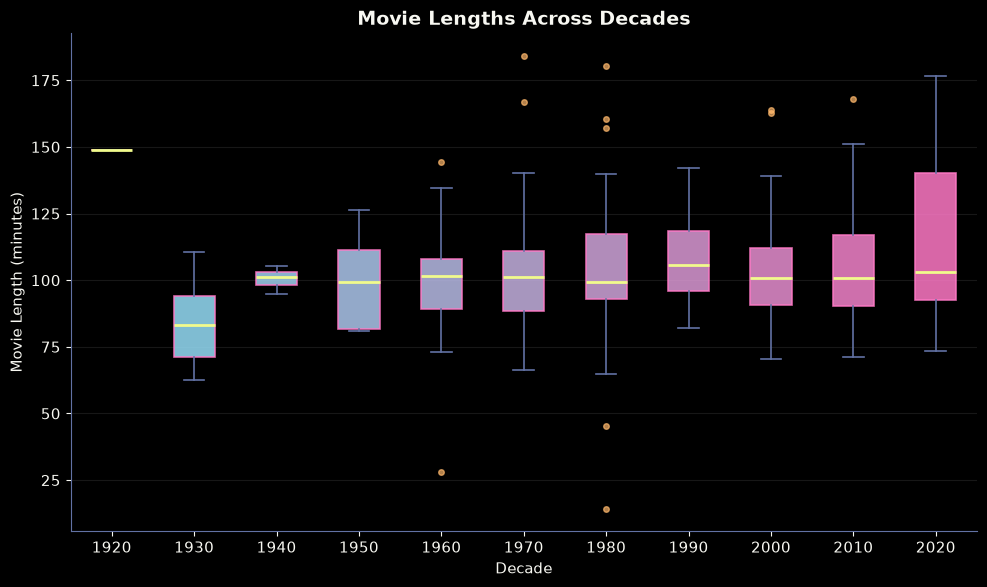

In [31]:
movie_lengths_with_decades: list[tuple[float, int | None]] = []
for year, length in movies:
    if length is None or not year:
        continue
    try:
        year_int = int(year)
    except ValueError:
        continue
    movie_lengths_with_decades.append((length / 60, (year_int // 10) * 10))

lengths_by_decade: dict[int, list[float]] = {}
for length_minutes, decade in movie_lengths_with_decades:
    lengths_by_decade.setdefault(decade, []).append(length_minutes)

decades = sorted(lengths_by_decade.keys())
lengths_data = [lengths_by_decade[d] for d in decades]

fig, ax = plt.subplots(figsize=(10, 6))
boxplot = ax.boxplot(
    lengths_data,
    tick_labels=decades,
    patch_artist=True,
    medianprops={"color": DRACULA["yellow"], "linewidth": 2},
    whiskerprops={"color": DRACULA["comment"], "linewidth": 1.2},
    capprops={"color": DRACULA["comment"], "linewidth": 1.2},
    flierprops={
        "marker": "o",
        "markerfacecolor": DRACULA["orange"],
        "markeredgecolor": DRACULA["orange"],
        "markersize": 4,
        "alpha": 0.7,
    },
)
for index, box in enumerate(boxplot["boxes"]):
    box.set_facecolor(DRACULA_CMAP(index / max(len(decades) - 1, 1)))
    box.set_edgecolor(DRACULA["pink"])
    box.set_alpha(0.85)
    box.set_linewidth(1.2)

ax.set_xlabel("Decade")
ax.set_ylabel("Movie Length (minutes)")
ax.set_title("Movie Lengths Across Decades")
style_axes(ax)
fig.tight_layout()
plt.show()